# Simulation: Fig. 2, Supplementary Fig. S2 and Supplementary Table 2

Every result of the simulation in the paper, computed from the deposited data and fit. Run from top to bottom.

- Simulated data: `data/simulation/back_0.5_dropout/`, made by `preprocess/simulation/simulation_datasets.ipynb`. The clone of each cell and the read counts were drawn without a seed, so the deposited files are the reference; section 1 checks that they follow the rules of the simulation.
- Fit: `output/v2/simulation/202610/11/080706`, trained by `retrain/train_simulation.py` (settings in section 2). The allele frequency is not decomposed into a shared and a clone-specific part (the simulation has no background variant).
- Output: `analysis/results/simulation/`, one PDF per panel, Fig. 2 and Supplementary Fig. S2 assembled from them, and the tables below as CSV.

In [1]:
%cd ../src

.../cloneVI/src


.../site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import os
import ast
import json

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

In [3]:
SIM = '../data/simulation/back_0.5_dropout'
RUN = '../output/v2/simulation/202610/11/080706'
OUT = '../analysis/results/simulation'
os.makedirs(OUT, exist_ok=True)

### Figure style

The same in every notebook of the paper. Panels are drawn at their print size, so that text and points match in the assembled figures. Every UMAP panel has the same size and frame. Colours of the UMAP panels as in the original analysis notebooks: clonal probability and VAF in cubehelix maps (from 0 to the largest value of the panel), two clones in the end colours of viridis, expression in viridis. Heatmaps keep the colour maps of the original notebooks (for $\phi$ the seaborn default).

In [4]:
plt.rcParams.update({'font.size': 6.5, 'axes.titlesize': 7, 'axes.labelsize': 6.5, 'xtick.labelsize': 6,
                     'ytick.labelsize': 6, 'legend.fontsize': 6, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5,
                     'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2, 'savefig.dpi': 600})
PI_CMAP = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
VAF_CMAP = sns.cubehelix_palette(as_cmap=True)
EXPR_CMAP = 'viridis'
MAP_SIZE = (2.0, 1.6)    # inches, every UMAP panel: map 1.36 in wide, colour bar or legend on the right


def new_map():
    fig = plt.figure(figsize=MAP_SIZE)
    ax = fig.add_axes([0.01, 0.02, 0.68, 0.84])
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    return fig, ax


def map_values(xy, v, cmap, title, label, s, vmin=0, vmax=None):
    # continuous values, high values drawn on top
    fig, ax = new_map()
    vmax = float(np.max(v)) if vmax is None else vmax
    o = np.argsort(v)
    ax.scatter(xy[o, 0], xy[o, 1], c=v[o], cmap=cmap, vmin=vmin, vmax=vmax, s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    cb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), cmap), cax=fig.add_axes([0.72, 0.12, 0.03, 0.62]))
    cb.outline.set_visible(False)
    cb.set_label(label)
    ax.set_title(title)
    return fig, ax


def map_groups(xy, groups, colors, title, s, labels=None, on_data=False, legend=True, seed=0):
    # categories, cells drawn in a fixed random order so that no group hides another
    fig, ax = new_map()
    o = np.random.default_rng(seed).permutation(len(groups))
    ax.scatter(xy[o, 0], xy[o, 1], c=[colors[g] for g in groups[o]], s=s, linewidths=0, rasterized=RASTER)
    ax.set_aspect('equal', adjustable='datalim')
    labels = labels or {g: str(g) for g in colors}
    if on_data:
        for g in colors:
            x, y = np.median(xy[groups == g], axis=0)
            ax.text(x, y, labels[g], ha='center', va='center', fontweight='bold',
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    elif legend:
        ax.legend(handles=legend_handles(colors, labels), loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False,
                  handletextpad=0.1)
    ax.set_title(title)
    return fig, ax


def legend_handles(colors, labels):
    return [Line2D([], [], marker='o', ls='', markersize=3, color=colors[g], label=labels[g]) for g in colors]


def legend_panel(colors, labels, ncol=1):
    # a legend as its own panel, for maps with many groups
    fig, ax = plt.subplots(figsize=(0.5, 0.5))
    ax.axis('off')
    ax.legend(handles=legend_handles(colors, labels), loc='center', ncol=ncol, frameon=False, handletextpad=0.1,
              columnspacing=1.0)
    return fig


def save(fig, name):
    # maps keep their fixed size; other panels are cropped to their content
    fixed = fig.get_size_inches().tolist() == list(MAP_SIZE)
    fig.savefig(f'{OUT}/{name}.pdf', bbox_inches=None if fixed else 'tight')

In [5]:
S = 2                                   # point size of the UMAP panels (2,638 cells)
RASTER = False                          # few cells: points stay vector
CLONE_COL = {0: plt.cm.viridis(0.0), 1: plt.cm.viridis(1.0)}
CLONE_NAME = {0: 'Clone 0', 1: 'Clone 1'}

## 1. The simulated data

Each cell of the Scanpy PBMC3k data was assigned to one of two clones with a probability fixed for its Louvain cluster, and was given the mutation counts of its clone: a depth $d \sim \mathrm{Poisson}(80)$ at each of six loci and mutant counts $b = r \odot d$, where $r$ is the 0/1 mutation profile of the clone (Methods, Supplementary Table 2).

In [6]:
adata = sc.read_h5ad(f'{SIM}/adata.h5ad')          # PBMC3k (processed): UMAP and Louvain clusters
adata_mg = sc.read_h5ad(f'{SIM}/adata_mg.h5ad')    # X = depth, layers['all_mut'] = mutant counts, obs['clone']
adata_mg

AnnData object with n_obs × n_vars = 2638 × 6
    obs: 'n_genes', 'percent_mito', 'n_counts', 'louvain', 'clone'
    uns: 'clone_colors', 'louvain_colors'
    layers: 'all_mut'

In [7]:
(adata.obs_names == adata_mg.obs_names).all()

True

### Expression input

The fit used the raw counts of these cells and genes; the processed object holds scaled values.

In [8]:
raw = sc.read_10x_mtx('../data/simulation/filtered_gene_bc_matrices/hg19', var_names='gene_symbols', cache=True)
raw.var_names_make_unique()
counts = raw[adata.obs_names, adata.var_names].X
counts.shape, bool(np.all(counts.data == np.round(counts.data))), adata.obs['louvain'].nunique()

((2638, 1838), True, 8)

### Mutation profiles

The profile $r_k$ of each clone, read back from the data: the fraction of the cells of each clone with mutant reads at each locus.

In [9]:
D = np.asarray(adata_mg.X)
B = np.asarray(adata_mg.layers['all_mut'])
clone = adata_mg.obs['clone'].astype(int).to_numpy()
r = pd.DataFrame([(B[clone == k] > 0).mean(0) for k in (0, 1)], index=['r_0', 'r_1'],
                 columns=[f'locus {m}' for m in range(D.shape[1])])
r

,locus 0,locus 1,locus 2,locus 3,locus 4,locus 5
r_0,0.0,1.0,0.0,0.0,1.0,1.0
r_1,0.0,1.0,1.0,1.0,0.0,0.0


No background and no dropout: the mutant counts equal $r \odot d$ exactly.

In [10]:
R = r.to_numpy()
np.array_equal(B, R[clone] * D)

True

### Depth

In [11]:
pd.Series({'mean': D.mean(), 'min': D.min(), 'max': D.max()}).round(2)

mean     79.96
min      47.00
max     112.00
dtype: float64

### Clonal probability of each cluster

Three clusters were set by hand (CD4 T cells clone 0 only, CD14+ monocytes clone 1 only, B cells half and half); the other five were drawn with `default_rng(1234)`. Drawing them again gives the deposited values.

In [12]:
probs = json.load(open(f'{SIM}/cluster_probs.json'))
cats = list(adata.obs['louvain'].cat.categories)
raw_probs = np.random.default_rng(1234).random((len(cats), 2))
redrawn = dict(zip(cats, (raw_probs / raw_probs.sum(1, keepdims=True)).tolist()))
BY_HAND = ['CD4 T cells', 'CD14+ Monocytes', 'B cells']
seed_ok = all(np.allclose(probs[c], redrawn[c]) for c in cats if c not in BY_HAND)
seed_ok

True

The specified probability of clone 0 and the fraction of cells actually drawn into clone 0, per cluster (numbered as in Fig. 2a).

In [13]:
louvain = adata.obs['louvain'].to_numpy()
clusters = pd.DataFrame({'cluster': range(len(cats)),
                         'cells': [int((louvain == c).sum()) for c in cats],
                         'clone 0 probability': [probs[c][0] for c in cats],
                         'clone 0 fraction drawn': [np.mean(clone[louvain == c] == 0) for c in cats]}, index=cats)
clusters.round(3)

,cluster,cells,clone 0 probability,clone 0 fraction drawn
CD4 T cells,0,1144,1.000,1.000
CD14+ Monocytes,1,480,0.000,0.000
B cells,2,342,0.500,0.558
CD8 T cells,3,316,0.431,0.418
NK cells,4,154,0.785,0.831
FCGR3A+ Monocytes,5,150,0.420,0.387
Dendritic cells,6,37,0.500,0.459
Megakaryocytes,7,15,0.506,0.400


### The resulting clones

In [14]:
n_clone = pd.Series(clone).value_counts().sort_index()
n_clone

0    1676
1     962
Name: count, dtype: int64

In [15]:
clusters.assign(**{'clone 1 probability': [probs[c][1] for c in cats]}).to_csv(f'{OUT}/supptable2_clusters.csv')

## 2. The fit

Settings recorded by the run. `lmd_pi` and `lmd_phi` are recorded, but no regularization stage was run (`use_sparse_term` is False), so they had no effect.

In [16]:
params = {}
for line in open(f'{RUN}/used_parameters.txt'):
    key, value = line.rstrip('\n').split(': ', 1)
    try:
        params[key] = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        params[key] = value
fit = pd.Series({'K (candidate clones)': params['model_params']['k'], 'learning rate': params['lr'],
                 'warm-up epochs': params['warmup_epochs'], 'max epochs per stage': params['epoch_num'],
                 'initial temperature, KL': params['loss_hparams']['kld_temp'],
                 'initial temperature, mutation': params['loss_hparams']['binom_temp'],
                 'regularization stage': params['use_sparse_term'], 'seed': params['seed']}, dtype=object)
fit

K (candidate clones)                10
learning rate                    0.001
warm-up epochs                    3000
max epochs per stage             20000
initial temperature, KL            100
initial temperature, mutation      100
regularization stage             False
seed                                42
dtype: object

In [17]:
res = sc.read_h5ad(f'{RUN}/cloneVI_result.h5ad')
assert (res.obs_names == adata.obs_names).all()
res

AnnData object with n_obs × n_vars = 2638 × 6
    obs: 'n_genes', 'percent_mito', 'n_counts', 'louvain', 'clone'
    uns: 'alpha', 'clone_colors', 'louvain_colors'
    obsm: 'X_cloneVI_umap', 'pi_deleted', 'pi_sorted', 'z'
    varm: 'phi_0', 'phi_deleted', 'phi_k', 'phi_sorted', 'phi_specific'
    layers: 'all_mut', 'reconst_VAF'

After training, a clone is kept if its mean $\pi$ is at least 0.01 or its largest $\pi$ is at least 0.2 (Methods). Of the ten candidate clones, two are kept.

In [18]:
pi_all = np.asarray(res.obsm['pi_sorted'], dtype=float)
pd.DataFrame({'mean pi': pi_all.mean(0), 'max pi': pi_all.max(0)}).round(4)

,mean pi,max pi
0,0.6388,0.9999
1,0.3612,0.9997
2,0.0000,0.0001
3,0.0000,0.0001
4,0.0000,0.0001
5,0.0000,0.0001
6,0.0000,0.0001
7,0.0000,0.0001
8,0.0000,0.0001
9,0.0000,0.0000


In [19]:
pi = np.asarray(res.obsm['pi_deleted'], dtype=float)
pi.shape

(2638, 2)

The model numbers its clones in its own order. The mean $\pi$ of the cells of each simulated clone shows that estimated clone 0 is simulated clone 0.

In [20]:
pd.DataFrame([pi[clone == k].mean(0) for k in (0, 1)], index=['simulated clone 0', 'simulated clone 1'],
             columns=['estimated clone 0', 'estimated clone 1']).round(3)

,estimated clone 0,estimated clone 1
simulated clone 0,0.834,0.166
simulated clone 1,0.299,0.701


## 3. Fig. 2a: the simulation on the PBMC3k UMAP

Left: the Louvain clusters, numbered as in the call-outs. Right: the simulated clone of each cell. The call-outs give the clonal probability of clusters 0, 1 and 2 (table in section 1); the mutation schematic is drawn by hand.

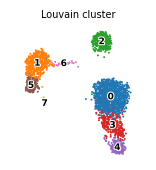

In [21]:
xy_pbmc = adata.obsm['X_umap']
louvain_num = adata.obs['louvain'].cat.codes.to_numpy()
fig, ax = map_groups(xy_pbmc, louvain_num, dict(enumerate(adata.uns['louvain_colors'])), 'Louvain cluster', S, on_data=True)
save(fig, 'fig2a_louvain')

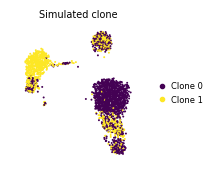

In [22]:
fig, ax = map_groups(xy_pbmc, clone, CLONE_COL, 'Simulated clone', S, labels=CLONE_NAME)
save(fig, 'fig2a_clone')

## 4. Fig. 2b: simulated clones and estimated clonal probabilities on the CloneVI UMAP

The UMAP of the cell state $z$ inferred by CloneVI.

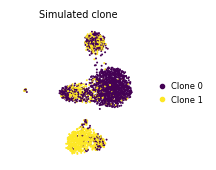

In [23]:
xy = res.obsm['X_cloneVI_umap']
fig, ax = map_groups(xy, clone, CLONE_COL, 'Simulated clone', S, labels=CLONE_NAME)
save(fig, 'fig2b_clone')

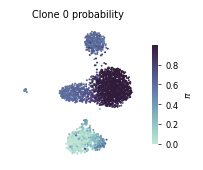

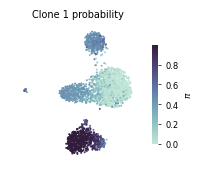

In [24]:
for k in (0, 1):
    fig, ax = map_values(xy, pi[:, k], PI_CMAP, f'Clone {k} probability', r'$\pi$', S)
    save(fig, f'fig2b_pi_clone{k}')

## 5. Fig. 2c: clonal probability by cluster type

The cells are grouped into the cluster of clone 0 only (CD4 T cells), the cluster of clone 1 only (CD14+ monocytes) and the six mixed clusters, and the clonal probabilities of the cells of each group are summed.

In [25]:
TYPES = ['clone 0 only (CD4 T)', 'clone 1 only (CD14+ Mono)', 'mixed (other 6)']
cluster_type = np.select([louvain == 'CD4 T cells', louvain == 'CD14+ Monocytes'], TYPES[:2], TYPES[2])
pi_sum = pd.DataFrame([pi[cluster_type == t].sum(0) for t in TYPES], index=TYPES, columns=['Clone 0', 'Clone 1'])
pi_sum.round(1)

,Clone 0,Clone 1
clone 0 only (CD4 T),1097.0,47.0
clone 1 only (CD14+ Mono),23.9,456.1
mixed (other 6),564.3,449.7


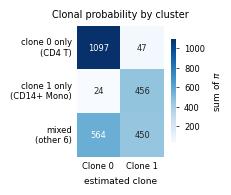

In [26]:
pi_sum.to_csv(f'{OUT}/fig2c_pi_sum_by_cluster_type.csv')
fig, ax = plt.subplots(figsize=(1.9, 1.7))
sns.heatmap(pi_sum.rename(index=lambda t: t.replace(' (', '\n(')), annot=True, fmt='.0f', cmap='Blues', square=True, ax=ax, annot_kws={'size': 6},
            cbar_kws={'label': r'sum of $\pi$', 'shrink': 0.8})
ax.set_xlabel('estimated clone')
ax.tick_params(length=0)
ax.set_title('Clonal probability by cluster')
save(fig, 'fig2c_pi_sum_by_cluster_type')

Taken together, the mixed clusters: the fraction of their cells drawn into clone 0, and the share of their summed probability given to clone 0.

In [27]:
mixed = cluster_type == TYPES[2]
pd.Series({'clone 0 fraction drawn': np.mean(clone[mixed] == 0),
           'clone 0 share of summed pi': pi[mixed, 0].sum() / pi[mixed].sum()}).round(3)

clone 0 fraction drawn        0.525
clone 0 share of summed pi    0.556
dtype: float64

The same comparison for each cluster: the fraction of its cells drawn into clone 0 and their mean $\pi$ of clone 0 (Results: in mixed clusters "the probabilities were split between the two clones in proportions close to the assigned mixture").

In [28]:
per_cluster = clusters.assign(**{'clone 0 mean pi': [pi[louvain == c, 0].mean() for c in cats]})
per_cluster.to_csv(f'{OUT}/fig2_per_cluster_pi.csv')
per_cluster.round(3)

,cluster,cells,clone 0 probability,clone 0 fraction drawn,clone 0 mean pi
CD4 T cells,0,1144,1.000,1.000,0.959
CD14+ Monocytes,1,480,0.000,0.000,0.050
B cells,2,342,0.500,0.558,0.572
CD8 T cells,3,316,0.431,0.418,0.704
NK cells,4,154,0.785,0.831,0.583
FCGR3A+ Monocytes,5,150,0.420,0.387,0.270
Dendritic cells,6,37,0.500,0.459,0.241
Megakaryocytes,7,15,0.506,0.400,0.463


## 6. Fig. 2d–e: clone proportions in the whole data

Ground truth: the fraction of cells in each simulated clone. Estimated: the mean clonal probability of each clone.

In [29]:
fractions = pd.DataFrame({'ground truth (%)': 100 * n_clone.to_numpy() / len(clone), 'estimated (%)': 100 * pi.mean(0)},
                         index=['Clone 0', 'Clone 1'])
fractions.to_csv(f'{OUT}/fig2de_fractions.csv')
fractions.round(2)

,ground truth (%),estimated (%)
Clone 0,63.53,63.88
Clone 1,36.47,36.12


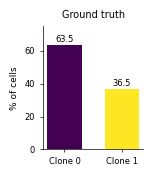

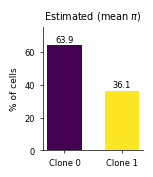

In [30]:
for name, col, title in [('fig2d_fraction_ground_truth', 'ground truth (%)', 'Ground truth'),
                         ('fig2e_fraction_estimated', 'estimated (%)', 'Estimated (mean $\\pi$)')]:
    fig, ax = plt.subplots(figsize=(1.3, 1.6))
    bars = ax.bar(fractions.index, fractions[col], color=[CLONE_COL[0], CLONE_COL[1]], width=0.6)
    ax.bar_label(bars, fmt='%.1f', fontsize=6, padding=1)
    ax.set_ylim(0, 75)
    ax.set_ylabel('% of cells')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(title)
    save(fig, name)

## 7. Supplementary Fig. S2: the simulated mutation data

VAF = mutant reads / depth, for the six mutations in every cell.

In [31]:
vaf = B / D
vaf.min(), vaf.max(), np.unique(vaf).size

(0.0, 1.0, 2)

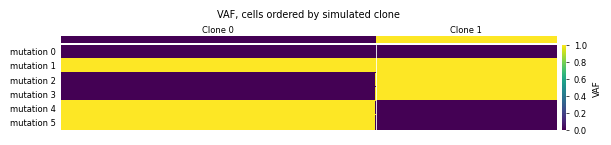

In [32]:
def vaf_heatmap(groups, colors, labels, title):
    # cells (columns) ordered by group; vector cells with face-coloured edges, so that no seams appear in PDF viewers
    o = np.argsort(groups, kind='stable')
    g = groups[o]
    fig, ax = plt.subplots(figsize=(6.6, 1.1))
    sns.heatmap(vaf[o].T, cmap='viridis', vmin=0, vmax=1, xticklabels=False, ax=ax, linewidths=0.1, linecolor='face',
                yticklabels=[f'mutation {m}' for m in range(vaf.shape[1])],
                cbar_kws={'label': 'VAF', 'fraction': 0.02, 'pad': 0.01})
    ax.tick_params(axis='y', length=0)
    edges = np.flatnonzero(np.diff(g)) + 1
    for x in edges:
        ax.axvline(x, color='white', lw=0.6)
    narrow = 0                                       # labels of consecutive narrow groups are staggered
    for a, b in zip(np.r_[0, edges], np.r_[edges, len(g)]):
        ax.add_patch(Rectangle((a, -0.6), b - a, 0.45, color=colors[g[a]], clip_on=False, lw=0))
        narrow = narrow + 1 if b - a < 0.02 * len(g) else 0
        ax.text((a + b) / 2, -0.75 - 0.6 * (narrow % 2 == 0 and narrow > 0), labels[g[a]], ha='center', va='bottom', fontsize=6)
    ax.set_title(title, pad=20)
    return fig, ax


fig, ax = vaf_heatmap(clone, CLONE_COL, CLONE_NAME, 'VAF, cells ordered by simulated clone')
save(fig, 'supfig2a_vaf_by_clone')

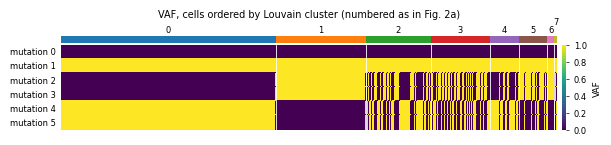

In [33]:
fig, ax = vaf_heatmap(louvain_num, dict(enumerate(adata.uns['louvain_colors'])), {i: str(i) for i in range(len(cats))},
                      'VAF, cells ordered by Louvain cluster (numbered as in Fig. 2a)')
save(fig, 'supfig2b_vaf_by_louvain')

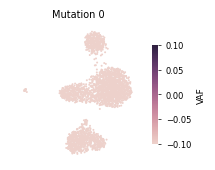

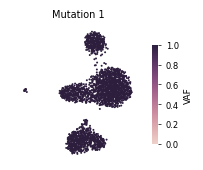

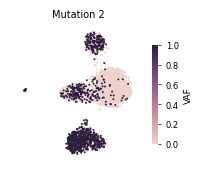

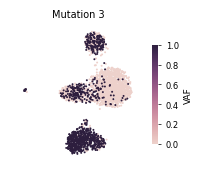

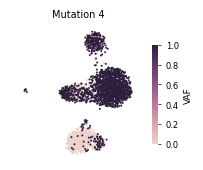

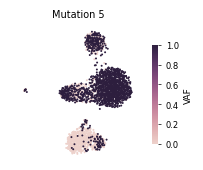

In [34]:
for m in range(vaf.shape[1]):
    fig, ax = map_values(xy, vaf[:, m], VAF_CMAP, f'Mutation {m}', 'VAF', S)
    save(fig, f'supfig2c_vaf_mutation{m}')

## 8. The numbers in the paper

Every number of the simulation quoted in the paper, next to the value computed above. `where` names the part of the paper: the Results section, a figure legend or alt text, a supplementary table or the Methods subsection.

In [35]:
pair = lambda p: f'({p[0]:.2f}, {p[1]:.2f})'
profile = lambda row: '(' + ','.join(str(int(x)) for x in row) + ')'
PAPER_PROBS = {'CD4 T cells': '(1.00, 0.00)', 'CD14+ Monocytes': '(0.00, 1.00)', 'B cells': '(0.50, 0.50)',
               'CD8 T cells': '(0.43, 0.57)', 'NK cells': '(0.79, 0.21)', 'FCGR3A+ Monocytes': '(0.42, 0.58)',
               'Dendritic cells': '(0.50, 0.50)', 'Megakaryocytes': '(0.51, 0.49)'}
T3, T2 = 'Supp. Table 3', 'Supp. Table 2'
rows = [('cells', T3, '2,638', f'{adata.n_obs:,}'),
        ('genes (raw counts)', T3, '1,838', f'{counts.shape[1]:,}'),
        ('Louvain clusters', f'{T3}; Methods (Generation of simulation data)', '8', str(len(cats))),
        ('clones', T3, '2', str(len(n_clone))),
        ('loci M', f'{T3}; {T2}', '6', str(D.shape[1])),
        ('r_0', T3, '(0,1,0,0,1,1)', profile(R[0])),
        ('r_1', T3, '(0,1,1,1,0,0)', profile(R[1])),
        ('depth', f'{T3}; Methods (Generation of simulation data)', 'Poisson(80)', f'mean {D.mean():.2f}'),
        ('b = r * d, no background, no dropout', T3, 'exact', 'exact' if np.array_equal(B, R[clone] * D) else 'no')]
rows += [(f'clonal probability, {c}', T3, PAPER_PROBS[c], pair(probs[c])) for c in cats]
rows += [('seed 1234 gives the five drawn probabilities', T3, 'yes', 'yes' if seed_ok else 'no'),
         ('Clone 0 cells', T3, '1,676', f'{n_clone[0]:,}'),
         ('Clone 1 cells', T3, '962', f'{n_clone[1]:,}'),
         ('K', f'{T2}; Methods (Pruning of clones)', '10', str(fit['K (candidate clones)'])),
         ('sample indicator', T2, 'none', 'none' if not params['use_multisamples'] else 'used'),
         ('decomposition of phi', T2, 'no', 'yes' if params['model_params']['use_phi_common'] else 'no'),
         ('regularization', T2, 'none', 'none' if not fit['regularization stage'] else 'used'),
         ('clone proportions, ground truth (%)', 'Fig. 2 alt text', 'about 64 / 36',
          '{:.1f} / {:.1f}'.format(*fractions['ground truth (%)'])),
         ('clone proportions, estimated (%)', 'Fig. 2 alt text', 'about 64 / 36',
          '{:.1f} / {:.1f}'.format(*fractions['estimated (%)']))]
numbers = pd.DataFrame(rows, columns=['item', 'where', 'paper', 'computed'])
numbers['match'] = numbers['paper'] == numbers['computed']
numbers.loc[numbers['item'] == 'depth', 'match'] = abs(D.mean() - 80) < 0.5
numbers.loc[numbers['paper'].str.startswith('about'), 'match'] = [
    np.allclose(np.round(fractions[c]), [64, 36]) for c in fractions.columns]
numbers.to_csv(f'{OUT}/numbers.csv', index=False)
pd.set_option('display.max_colwidth', 80)
numbers

,item,where,paper,computed,match
0,cells,Supp. Table 3,"2,638","2,638",True
1,genes (raw counts),Supp. Table 3,"1,838","1,838",True
2,Louvain clusters,Supp. Table 3; Methods (Generation of simulation data),8,8,True
3,clones,Supp. Table 3,2,2,True
4,loci M,Supp. Table 3; Supp. Table 2,6,6,True
5,r_0,Supp. Table 3,"(0,1,0,0,1,1)","(0,1,0,0,1,1)",True
6,r_1,Supp. Table 3,"(0,1,1,1,0,0)","(0,1,1,1,0,0)",True
7,depth,Supp. Table 3; Methods (Generation of simulation data),Poisson(80),mean 79.96,True
8,"b = r * d, no background, no dropout",Supp. Table 3,exact,exact,True
9,"clonal probability, CD4 T cells",Supp. Table 3,"(1.00, 0.00)","(1.00, 0.00)",True


In [36]:
numbers['match'].all()

True

## 9. Supplementary Fig. S2 as a figure

The panels of section 7 as one figure at the text width, with the sizes shared by all figures (as in `03e_cll_figure4.ipynb`): the two heatmaps across the text width, and the six maps of the VAF on the CloneVI UMAP, four in the first row and two in the second, all of one size.

In [37]:
# sizes shared by all figures (points), as in 03e_cll_figure4.ipynb
W = 505.69                          # text width
M = 1                               # outer margin, so that frames at the edge are drawn whole
MB = 4                              # bottom margin below a map: half of its lowest colorbar label hangs below it
LG = 9                              # letter column at the left of every column (the gap between columns)
CL = 3                              # clearance at the right of a panel that has no colorbar beside it
GY = 6                              # gap between rows
T = 11                              # title row above a panel; titles and letters stand on its baseline
PAD = 3                             # baseline of the titles above the axes
CB_W, CB_PAD, CB_ROOM = 4, 3, 26    # colorbar beside a map: width, distance, and the room it takes with its labels
SW = (W - 2 * M) / 4                # width of a column (4 columns), letter column included
MW = SW - LG - CB_ROOM              # width of a map
LH = 1.2 * plt.rcParams['axes.titlesize']   # height of a line of a title
plt.rcParams['axes.titlepad'] = PAD

figure 505.69 x 409.6 pt; maps 90.9 x 103.3 pt (point size 6.41); heatmaps 432.7 x 48 pt


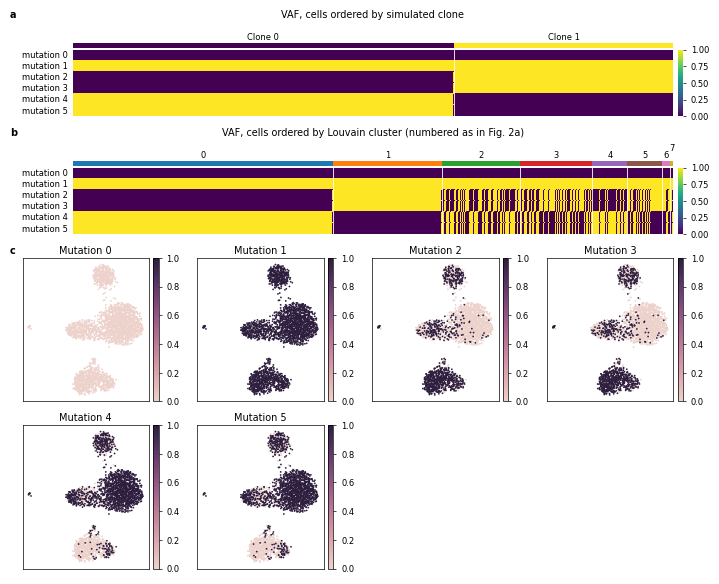

In [38]:
nm = vaf.shape[1]
cells = sc.AnnData(obs=pd.DataFrame(index=np.arange(len(xy)).astype(str)))
cells.obsm['X_umap'] = np.asarray(xy)
for m in range(nm):
    cells.obs[f'Mutation {m}'] = vaf[:, m]
MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
SIZE = 1.8 * MW * MH / len(xy)
col = lambda j: M + j * SW
LM = 36                                              # names of the mutations
HC = 8                                               # height of a row of the heatmaps
BAR = 20                                             # above a heatmap: the bar of the groups and their names
HW = W - 2 * M - LG - LM - CB_ROOM                   # width of a heatmap
HB = T + BAR + nm * HC + GY                          # height of the block of a heatmap
y_c = M + 2 * HB
RH = T + MH + GY
H = y_c + 2 * RH - GY + MB
fig = plt.figure(figsize=(W / 72, H / 72))
axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
letter = lambda x, y, s: fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'],
                                  va='baseline')

def vaf_heatmap(y, groups, colors, labels, title):
    # cells (columns) ordered by group, with a bar of the groups above (as in section 7)
    o = np.argsort(groups, kind='stable')
    g = groups[o]
    ax = axes(M + LG + LM, y + T + BAR, HW, nm * HC)
    cax = axes(M + LG + LM + HW + CB_PAD, y + T + BAR, CB_W, nm * HC)
    sns.heatmap(vaf[o].T, cmap='viridis', vmin=0, vmax=1, xticklabels=False, ax=ax, linewidths=0.1, linecolor='face',
                yticklabels=[f'mutation {m}' for m in range(nm)], cbar_ax=cax)
    ax.tick_params(axis='y', length=0, rotation=0)
    edges = np.flatnonzero(np.diff(g)) + 1
    for x in edges:
        ax.axvline(x, color='white', lw=0.6)
    narrow = 0                                       # labels of consecutive narrow groups are staggered
    for a, b in zip(np.r_[0, edges], np.r_[edges, len(g)]):
        ax.add_patch(Rectangle((a, -0.6), b - a, 0.45, color=colors[g[a]], clip_on=False, lw=0))
        narrow = narrow + 1 if b - a < 0.02 * len(g) else 0
        ax.text((a + b) / 2, -0.75 - 0.6 * (narrow % 2 == 0 and narrow > 0), labels[g[a]], ha='center', va='bottom', fontsize=6)
    ax.set_title(title, pad=PAD + BAR)
    return ax

letter(M, M, 'a')
vaf_heatmap(M, clone, CLONE_COL, CLONE_NAME, 'VAF, cells ordered by simulated clone')
letter(M, M + HB, 'b')
vaf_heatmap(M + HB, louvain_num, dict(enumerate(adata.uns['louvain_colors'])), {i: str(i) for i in range(len(cats))},
            'VAF, cells ordered by Louvain cluster (numbered as in Fig. 2a)')
letter(M, y_c, 'c')
for m in range(nm):
    x, y = col(m % 4) + LG, y_c + (m // 4) * RH
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=f'Mutation {m}', ax=ax, basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None,
                    cmap=VAF_CMAP, vmin=0, vmax=1)
    ax.set_xlabel(''); ax.set_ylabel('')
    fig.colorbar(ax.collections[0], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
fig.savefig(f'{OUT}/supfig2.pdf')
fig.savefig(f'{OUT}/supfig2.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt (point size {SIZE:.2f}); heatmaps {HW:.1f} x {nm * HC} pt')

## 10. Fig. 2

The panels of sections 4–6 as one figure at the text width, with the sizes shared by all figures (as in `03e_cll_figure4.ipynb`). a, the simulation on the PBMC3k UMAP with the schematic of the mutation profiles, drawn by hand and placed as an image (`analysis/figure_parts/fig2a_schematic.png`) at the width of its region (columns 1-3 of rows 1-2). b, the simulated clones and the clonal probabilities on the CloneVI UMAP; c, the summed clonal probability by cluster type (the types by their clones only, as a shows the clusters by their percentages); d, e, the clone proportions (ground truth and estimated).

.../site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
.../site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


figure 505.69 x 335.1 pt; maps 90.9 x 103.3 pt; c cells 33.1 pt; bar plots 88.9 x 63.5 pt; a 365.8 x 197.1 pt (3094 x 1667 px, 609 dpi)


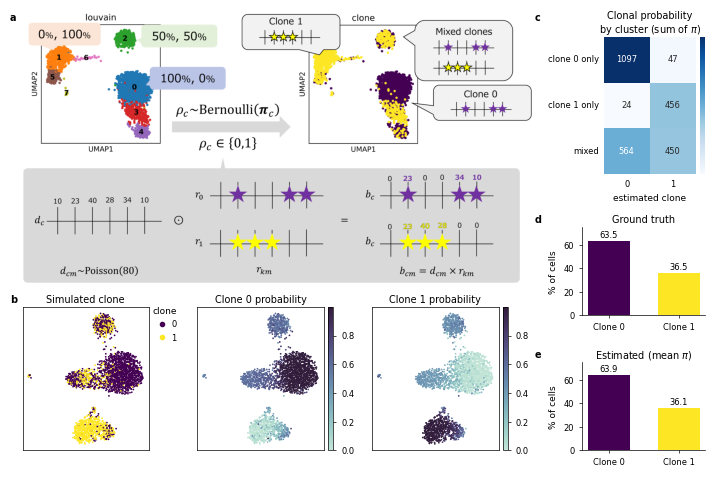

In [39]:
cells = sc.AnnData(obs=pd.DataFrame(index=np.arange(len(xy)).astype(str)))
cells.obsm['X_umap'] = np.asarray(xy)
cells.obs['Simulated clone'] = pd.Categorical([CLONE_NAME[k] for k in clone], categories=list(CLONE_NAME.values()))
for k in (0, 1):
    cells.obs[f'Clone {k} probability'] = pi[:, k]
MH = MW * np.ptp(xy[:, 1]) / np.ptp(xy[:, 0])
SIZE = 1.8 * MW * MH / len(xy)
col = lambda j: M + j * SW
RH = T + MH + GY
# a (drawn by hand, an image) in columns 0-2, and b (three maps) directly below it; column 3: c, d and e stacked, the
# bottom of e level with the bottom of the maps of b. d and e are bar plots of the same quantity, so they are of one height
import matplotlib.image as mpimg
schematic = mpimg.imread('../analysis/figure_parts/fig2a_schematic.png')
AW = 3 * SW - LG - CL                                 # a: the width of three columns
AH = AW * schematic.shape[0] / schematic.shape[1]
y_b = M + AH + GY                                     # top of the row of b and e
# c: the cluster types by their clones only (a shows the clusters by their percentages, not by cell type)
pi_c = pi_sum.rename(index=lambda t: t.split(' (')[0], columns=lambda c: c.split()[-1])
f_ = plt.figure()
tw = lambda t: f_.text(0, 0, t, fontsize=plt.rcParams['ytick.labelsize']).get_window_extent(f_.canvas.get_renderer()).width * 72 / f_.dpi
LC = 4 + max(tw(t) for t in pi_c.index)               # c: the row names, measured
CB_C = CB_PAD + CB_W + CL                             # c: its colorbar, without labels (the values are written in the cells)
plt.close(f_)
cc = (SW - LG - LC - CB_C) / 2                       # c: square cells, as large as fit in column 3
BXC = 2 + 1.2 * 6 + 4 + 1.2 * 6.5                     # below c: tick labels and the x label
BXB = 2 + 3.5 + 1.2 * 6 + 4                           # below a bar plot: ticks and tick labels
y_d = M + T + LH + 3 * cc + BXC + GY                  # top of d
y_bot = y_b + T + MH                                  # bottom of the maps of b, and of e
blk = (y_bot + BXB - y_d - GY) / 2                    # d and e, each: title row, bar plot and tick labels
BH = blk - T - BXB                                    # height of a bar plot
y_e = y_d + blk + GY                                  # top of e
BW = SW - LG - 25 - CL                                # width of a bar plot (y labels 25 pt)
H = y_bot + BXB                                       # the tick labels of e below the bottom of b
fig = plt.figure(figsize=(W / 72, H / 72))
axes = lambda x, y, w, h: fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
letter = lambda x, y, s: fig.text(x / W, 1 - (y + T - PAD) / H, s, fontweight='bold', fontsize=plt.rcParams['axes.titlesize'],
                                  va='baseline')
letter(col(0), M, 'a')
ax = axes(col(0) + LG, M, AW, AH)
ax.imshow(schematic)
ax.axis('off')

# b
letter(col(0), y_b, 'b')
emb = dict(basis='umap', show=False, frameon=True, size=SIZE, colorbar_loc=None)
for j, (color, kw) in enumerate([('Simulated clone', dict(palette=[CLONE_COL[0], CLONE_COL[1]], legend_loc=None)),
                                 ('Clone 0 probability', dict(cmap=PI_CMAP, vmin=0)), ('Clone 1 probability', dict(cmap=PI_CMAP, vmin=0))]):
    x, y = col(j) + LG, y_b
    ax = axes(x, y + T, MW, MH)
    sc.pl.embedding(cells, color=color, ax=ax, **emb, **kw)
    ax.set_xlabel(''); ax.set_ylabel('')
    if 'cmap' in kw:
        fig.colorbar(ax.collections[0], cax=axes(x + MW + CB_PAD, y + T, CB_W, MH))
    else:
        fig.legend(handles=[Line2D([], [], marker='o', ls='', markersize=3, color=CLONE_COL[k], label=str(k)) for k in (0, 1)],
                   title='clone', loc='upper left', bbox_to_anchor=((x + MW + CB_PAD) / W, 1 - (y + T) / H), frameon=False,
                   handletextpad=0.1, borderaxespad=0, borderpad=0)

# c: square cells, as large as fit in column 3 between the names and the colorbar
letter(col(3), M, 'c')
ax = axes(col(3) + LG + LC, M + T + LH, 2 * cc, 3 * cc)
cax = axes(col(3) + LG + LC + 2 * cc + CB_PAD, M + T + LH, CB_W, 3 * cc)
sns.heatmap(pi_c, annot=True, fmt='.0f', cmap='Blues', square=True, ax=ax, annot_kws={'size': 6}, cbar_ax=cax)
cax.tick_params(right=False, labelright=False)
ax.tick_params(axis='y', rotation=0)
ax.set_xlabel('estimated clone')
ax.tick_params(length=0)
ax.set_title('Clonal probability\nby cluster (sum of $\\pi$)')

# d, e
for lt, y, colname, title in [('d', y_d, 'ground truth (%)', 'Ground truth'), ('e', y_e, 'estimated (%)', 'Estimated (mean $\\pi$)')]:
    letter(col(3), y, lt)
    ax = axes(col(3) + LG + 25, y + T, BW, BH)
    bars = ax.bar(fractions.index, fractions[colname], color=[CLONE_COL[0], CLONE_COL[1]], width=0.6)
    ax.bar_label(bars, fmt='%.1f', fontsize=6, padding=1)
    ax.set_ylim(0, 75)
    ax.set_ylabel('% of cells')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(title)

fig.savefig(f'{OUT}/figure2.pdf')
fig.savefig(f'{OUT}/figure2.png', dpi=300)
print(f'figure {W} x {H:.1f} pt; maps {MW:.1f} x {MH:.1f} pt; c cells {cc:.1f} pt; bar plots {BW:.1f} x {BH:.1f} pt; a {AW:.1f} x {AH:.1f} pt '
      f'({schematic.shape[1]} x {schematic.shape[0]} px, {schematic.shape[1] / (AW / 72):.0f} dpi)')